# 6. Testable hypotheses for NYC Citi Bike (2013–2019)

**Who worked on this:** Rune Lemmens

This notebook tests three simple hypotheses using **only the station-day aggregate** produced by 04_aggregation.ipynb. The aggregate has one row per start station per day, so station rows are combined into daily totals/weighted means and the tests use complete calendar weeks as paired units.

The tests establish associations, not causal effects. The aggregate has no hour-of-day or destination-station fields, so the hypotheses are about weekday/weekend usage, duration, and rider-type mix—not rush hours or routes.

## 1. Load the station-day aggregate and form daily metrics

Read only columns from the aggregate CSV, then combine station-day rows into one daily record. For duration and rider mix, use trip counts as weights so high-volume station-days contribute proportionally. The aggregation output is small enough to summarize daily values while streaming in chunks.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

DATA_DIR = Path.cwd() / "data"
AGGREGATED_PATH = DATA_DIR / "processed" / "citibike_station_day_summary_2013_2019.csv"
RESULTS_PATH = DATA_DIR / "processed" / "citibike_hypothesis_results_2013_2019.csv"
CHUNK_SIZE = 200_000
RANDOM_SEED = 42
ALPHA = 0.05
N_PERMUTATIONS = 10_000
N_BOOTSTRAPS = 2_000

AGGREGATE_COLUMNS = [
    "trip_date", "start_station_id", "day_of_week", "trip_count",
    "mean_trip_duration_s", "member_trip_count",
]
if not AGGREGATED_PATH.exists():
    raise FileNotFoundError(
        f"Station-day aggregate not found: {AGGREGATED_PATH}. Run 04_aggregation.ipynb first."
    )
_header = pd.read_csv(AGGREGATED_PATH, nrows=0)
_missing = sorted(set(AGGREGATE_COLUMNS) - set(_header.columns))
if _missing:
    raise ValueError(f"Aggregate CSV is missing required columns: {_missing}")

# A dict keyed by date is bounded by the number of calendar days, not trip count.
daily_totals = {}
aggregate_rows_scanned = 0
for aggregate_chunk in pd.read_csv(
    AGGREGATED_PATH,
    usecols=AGGREGATE_COLUMNS,
    chunksize=CHUNK_SIZE,
    low_memory=False,
):
    aggregate_rows_scanned += len(aggregate_chunk)
    aggregate_chunk["trip_date"] = pd.to_datetime(aggregate_chunk["trip_date"], errors="coerce")
    for column in ("trip_count", "mean_trip_duration_s", "member_trip_count"):
        aggregate_chunk[column] = pd.to_numeric(aggregate_chunk[column], errors="coerce")
    aggregate_chunk = aggregate_chunk.dropna(subset=["trip_date", "trip_count", "day_of_week"])

    aggregate_chunk["duration_total_s"] = (
        aggregate_chunk["mean_trip_duration_s"] * aggregate_chunk["trip_count"]
    )
    aggregate_chunk["member_trip_count"] = aggregate_chunk["member_trip_count"].fillna(0)
    daily_chunk = aggregate_chunk.groupby("trip_date", observed=True).agg(
        trips=("trip_count", "sum"),
        duration_total_s=("duration_total_s", "sum"),
        member_trips=("member_trip_count", "sum"),
        day_of_week=("day_of_week", "first"),
    )
    for date, row in daily_chunk.iterrows():
        record = daily_totals.setdefault(date, {
            "trips": 0.0, "duration_total_s": 0.0, "member_trips": 0.0,
            "day_of_week": int(row["day_of_week"]),
        })
        record["trips"] += float(row["trips"])
        record["duration_total_s"] += float(row["duration_total_s"])
        record["member_trips"] += float(row["member_trips"])

daily = pd.DataFrame.from_dict(daily_totals, orient="index").rename_axis("trip_date").reset_index()
daily["trip_date"] = pd.to_datetime(daily["trip_date"])
daily["day_of_week"] = daily["day_of_week"].astype(int)
daily["is_weekend"] = daily["day_of_week"].ge(5)
daily["mean_duration_s"] = daily["duration_total_s"] / daily["trips"]
daily["member_share"] = daily["member_trips"] / daily["trips"]
daily["week_start"] = daily["trip_date"] - pd.to_timedelta(daily["day_of_week"], unit="D")

weekly_rows = []
for week_start, week in daily.groupby("week_start", sort=True):
    weekdays = week.loc[~week["is_weekend"]]
    weekends = week.loc[week["is_weekend"]]
    weekly_rows.append({
        "week_start": week_start,
        "days_present": int(week["trip_date"].nunique()),
        "weekday_days": len(weekdays),
        "weekend_days": len(weekends),
        "weekday_trips_per_day": float(weekdays["trips"].mean()) if len(weekdays) else np.nan,
        "weekend_trips_per_day": float(weekends["trips"].mean()) if len(weekends) else np.nan,
        "weekday_duration_s": float(np.average(weekdays["mean_duration_s"], weights=weekdays["trips"])) if len(weekdays) else np.nan,
        "weekend_duration_s": float(np.average(weekends["mean_duration_s"], weights=weekends["trips"])) if len(weekends) else np.nan,
        "weekday_member_share": float(weekdays["member_trips"].sum() / weekdays["trips"].sum()) if len(weekdays) and weekdays["trips"].sum() else np.nan,
        "weekend_member_share": float(weekends["member_trips"].sum() / weekends["trips"].sum()) if len(weekends) and weekends["trips"].sum() else np.nan,
    })
weekly = pd.DataFrame(weekly_rows)
complete_weeks = weekly.loc[
    weekly["days_present"].eq(7) & weekly["weekday_days"].eq(5) & weekly["weekend_days"].eq(2)
].dropna().reset_index(drop=True)
if len(complete_weeks) < 20:
    raise ValueError(f"Only {len(complete_weeks)} complete weeks; too few for paired weekly tests.")

print(f"Aggregate station-day rows scanned: {aggregate_rows_scanned:,}")
print(f"Daily records: {len(daily):,}")
print(f"Complete Monday–Sunday weeks used for inference: {len(complete_weeks):,}")
print(f"Aggregate source: {AGGREGATED_PATH}")

Aggregate station-day rows scanned: 1,297,662
Daily records: 2,397
Complete Monday–Sunday weeks used for inference: 339
Aggregate source: c:\Users\lemme\OneDrive\Desktop\2025_School\deep learning\Ctrl-Alt-Defeat\NYC Citi Bike System Data\data\processed\citibike_station_day_summary_2013_2019.csv


## 2. Test helpers

Use paired weekly differences to account for recurring week-to-week demand variation. A sign-flip permutation test evaluates a directional mean difference; a bootstrap over weeks gives a 95% confidence interval. These tests treat weeks as the independent units rather than treating millions of trips as independent observations.

In [13]:
test_rng = np.random.default_rng(RANDOM_SEED)


def paired_sign_flip_test(differences: np.ndarray) -> tuple[float, float]:
    """One-sided permutation test for a positive mean paired difference."""
    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]
    observed = float(differences.mean())
    exceedances = 0
    batch_size = 1000
    for start in range(0, N_PERMUTATIONS, batch_size):
        batch_n = min(batch_size, N_PERMUTATIONS - start)
        signs = test_rng.choice([-1.0, 1.0], size=(batch_n, len(differences)))
        exceedances += int(((signs * differences).mean(axis=1) >= observed).sum())
    return observed, (exceedances + 1) / (N_PERMUTATIONS + 1)


def bootstrap_mean_ci(differences: np.ndarray) -> tuple[float, float]:
    differences = np.asarray(differences, dtype=float)
    indices = test_rng.integers(0, len(differences), size=(N_BOOTSTRAPS, len(differences)))
    means = differences[indices].mean(axis=1)
    return tuple(np.quantile(means, [0.025, 0.975]))


def paired_effect_dz(differences: np.ndarray) -> float:
    differences = np.asarray(differences, dtype=float)
    standard_deviation = float(np.std(differences, ddof=1))
    return float(np.mean(differences) / standard_deviation) if standard_deviation else np.nan


def holm_adjust(p_values: list[float]) -> np.ndarray:
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running_max = 0.0
    for rank, index in enumerate(order):
        running_max = max(running_max, min(1.0, (len(p_values) - rank) * p_values[index]))
        adjusted[index] = running_max
    return adjusted


def format_p(value: float) -> str:
    return "< 1e-300 (numerical underflow)" if value == 0 else f"{value:.3g}"

## 3. Hypothesis 1: Weekend days have more trips per day

**H₀:** Mean trips per day are the same on weekends and weekdays.

**H₁:** Mean trips per day are higher on weekends. Compare each complete week's average weekend-day trip count with its average weekday trip count using a paired, one-sided sign-flip permutation test. This is a per-day comparison, not a total-count comparison, because each week has five weekdays but only two weekend days.

Complete weeks: 339
Weekday average: 40,792.5 trips/day
Weekend average: 32,920.8 trips/day
Paired difference (weekend − weekday): -7,871.7 trips/day
95% bootstrap CI: [-8,779.9, -6,932.7]
Cohen's dz: -0.909; one-sided permutation p-value: 1


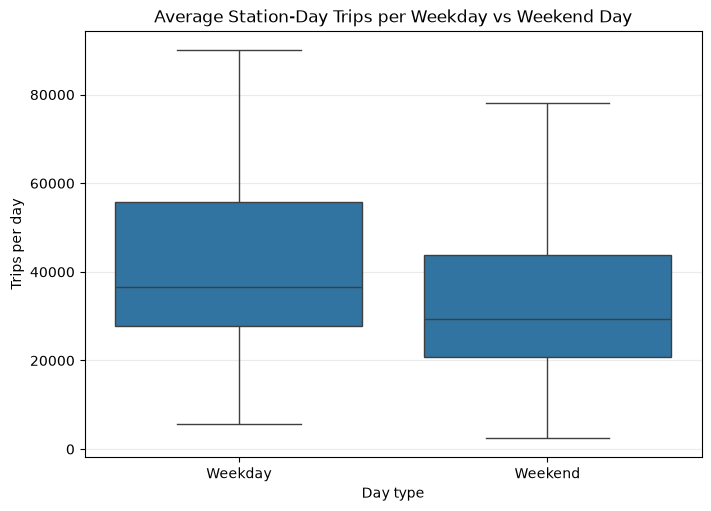

In [14]:
h1_differences = (
    complete_weeks["weekend_trips_per_day"] - complete_weeks["weekday_trips_per_day"]
).to_numpy()
h1_difference, h1_p = paired_sign_flip_test(h1_differences)
h1_ci = bootstrap_mean_ci(h1_differences)
h1_dz = paired_effect_dz(h1_differences)
h1_weekday_mean = float(complete_weeks["weekday_trips_per_day"].mean())
h1_weekend_mean = float(complete_weeks["weekend_trips_per_day"].mean())

print(f"Complete weeks: {len(complete_weeks):,}")
print(f"Weekday average: {h1_weekday_mean:,.1f} trips/day")
print(f"Weekend average: {h1_weekend_mean:,.1f} trips/day")
print(f"Paired difference (weekend − weekday): {h1_difference:,.1f} trips/day")
print(f"95% bootstrap CI: [{h1_ci[0]:,.1f}, {h1_ci[1]:,.1f}]")
print(f"Cohen's dz: {h1_dz:.3f}; one-sided permutation p-value: {format_p(h1_p)}")

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.boxplot(
    data=pd.DataFrame({"Weekday": complete_weeks["weekday_trips_per_day"], "Weekend": complete_weeks["weekend_trips_per_day"]}).melt(var_name="Day type", value_name="Trips per day"),
    x="Day type", y="Trips per day", showfliers=False, ax=ax,
)
ax.set_title("Average Station-Day Trips per Weekday vs Weekend Day")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 4. Hypothesis 2: Trips are longer on weekends

**H₀:** The trip-weighted mean duration is equal on weekdays and weekends.

**H₁:** Trip-weighted mean duration is longer on weekends. Station-day mean durations are weighted by their trip counts to recover daily trip-weighted means; compare weekly weekday/weekend means with a paired one-sided permutation test.

Weekday trip-weighted mean: 838.3 seconds
Weekend trip-weighted mean: 1013.6 seconds
Paired difference (weekend − weekday): 175.3 seconds
95% bootstrap CI: [162.3, 187.1]
Cohen's dz: 1.553; one-sided permutation p-value: 0.0001


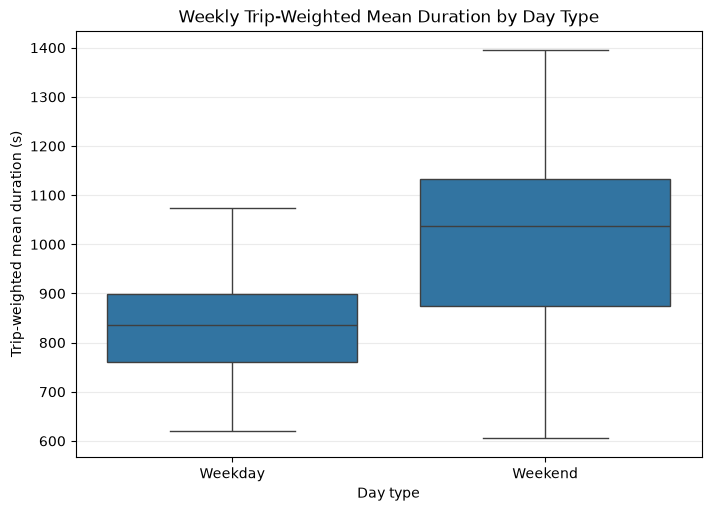

In [15]:
h2_differences = (
    complete_weeks["weekend_duration_s"] - complete_weeks["weekday_duration_s"]
).to_numpy()
h2_difference, h2_p = paired_sign_flip_test(h2_differences)
h2_ci = bootstrap_mean_ci(h2_differences)
h2_dz = paired_effect_dz(h2_differences)
h2_weekday_mean = float(complete_weeks["weekday_duration_s"].mean())
h2_weekend_mean = float(complete_weeks["weekend_duration_s"].mean())

print(f"Weekday trip-weighted mean: {h2_weekday_mean:.1f} seconds")
print(f"Weekend trip-weighted mean: {h2_weekend_mean:.1f} seconds")
print(f"Paired difference (weekend − weekday): {h2_difference:.1f} seconds")
print(f"95% bootstrap CI: [{h2_ci[0]:.1f}, {h2_ci[1]:.1f}]")
print(f"Cohen's dz: {h2_dz:.3f}; one-sided permutation p-value: {format_p(h2_p)}")

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.boxplot(
    data=pd.DataFrame({"Weekday": complete_weeks["weekday_duration_s"], "Weekend": complete_weeks["weekend_duration_s"]}).melt(var_name="Day type", value_name="Trip-weighted mean duration (s)"),
    x="Day type", y="Trip-weighted mean duration (s)", showfliers=False, ax=ax,
)
ax.set_title("Weekly Trip-Weighted Mean Duration by Day Type")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 5. Hypothesis 3: Member share is higher on weekdays

**H₀:** The member share of trips is equal on weekdays and weekends.

**H₁:** The member share is higher on weekdays. Calculate each week's trip-weighted member share for weekdays and weekends, then test the paired weekly difference. Member/casual counts come directly from the station-day aggregate.

Weekday member share: 92.09%
Weekend member share: 80.70%
Paired difference (weekday − weekend): 11.39%
95% bootstrap CI: [10.76%, 12.07%]
Cohen's dz: 1.786; one-sided permutation p-value: 0.0001


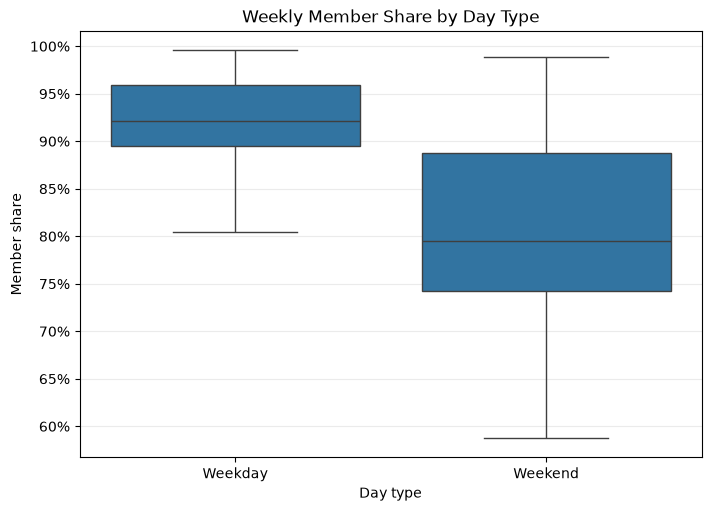

In [16]:
h3_differences = (
    complete_weeks["weekday_member_share"] - complete_weeks["weekend_member_share"]
).to_numpy()
h3_difference, h3_p = paired_sign_flip_test(h3_differences)
h3_ci = bootstrap_mean_ci(h3_differences)
h3_dz = paired_effect_dz(h3_differences)
h3_weekday_mean = float(complete_weeks["weekday_member_share"].mean())
h3_weekend_mean = float(complete_weeks["weekend_member_share"].mean())

print(f"Weekday member share: {h3_weekday_mean:.2%}")
print(f"Weekend member share: {h3_weekend_mean:.2%}")
print(f"Paired difference (weekday − weekend): {h3_difference:.2%}")
print(f"95% bootstrap CI: [{h3_ci[0]:.2%}, {h3_ci[1]:.2%}]")
print(f"Cohen's dz: {h3_dz:.3f}; one-sided permutation p-value: {format_p(h3_p)}")

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.boxplot(
    data=pd.DataFrame({"Weekday": complete_weeks["weekday_member_share"], "Weekend": complete_weeks["weekend_member_share"]}).melt(var_name="Day type", value_name="Member share"),
    x="Day type", y="Member share", showfliers=False, ax=ax,
)
ax.set_title("Weekly Member Share by Day Type")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.grid(axis="y", alpha=0.25)
plt.show()